## 1. Import library dan pengaturan

In [1]:
import shutil
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATASET_RAW = ROOT / "dataset_raw"
SELEKSI_CSV = ROOT / "hasil" / "seleksi_dataset" / "hasil_seleksi.csv"
HASIL = ROOT / "hasil" / "praproses"
OUT_IMG = ROOT / "data" / "praproses"

KELAS = ["logam", "paper", "plastic"]
UKURAN = 640          # ukuran akhir 640 x 640
MEDIAN_K = 3          # ukuran kernel median filter
CLAHE_CLIP = 2.0      # batas penguatan kontras CLAHE
JUMLAH_CONTOH = 2     # contoh per kelas yang ditampilkan di notebook
SIMPAN_SEMUA = True   # simpan gambar perbandingan untuk semua foto

## 2. Fungsi praproses

In [2]:
def baca(path, gray=False):
    """Membaca gambar (aman untuk path Windows). Hasil None jika gagal dibaca."""
    try:
        data = np.fromfile(str(path), np.uint8)
        return cv2.imdecode(data, cv2.IMREAD_GRAYSCALE if gray else cv2.IMREAD_COLOR)
    except Exception:
        return None


def tulis(path, img):
    """Menyimpan gambar (aman untuk path Windows)."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    ok, buf = cv2.imencode(path.suffix, img)
    buf.tofile(str(path))


def letterbox(img, ukuran=UKURAN):
    """Ubah ke ukuran x ukuran tanpa mengubah proporsi. Return kanvas dan kotak area foto (x1, y1, x2, y2)."""
    h, w = img.shape[:2]
    skala = ukuran / max(h, w)
    nw, nh = max(1, round(w * skala)), max(1, round(h * skala))
    interpolasi = cv2.INTER_AREA if skala < 1 else cv2.INTER_CUBIC
    kecil = cv2.resize(img, (nw, nh), interpolation=interpolasi)
    kanvas = np.full((ukuran, ukuran, 3), 114, np.uint8)
    x0, y0 = (ukuran - nw) // 2, (ukuran - nh) // 2
    kanvas[y0:y0 + nh, x0:x0 + nw] = kecil
    return kanvas, (x0, y0, x0 + nw, y0 + nh)


def median_filter(img):
    return cv2.medianBlur(img, MEDIAN_K)


def clahe(img):
    l, a, b = cv2.split(cv2.cvtColor(img, cv2.COLOR_BGR2LAB))
    l = cv2.createCLAHE(clipLimit=CLAHE_CLIP, tileGridSize=(8, 8)).apply(l)
    return cv2.cvtColor(cv2.merge((l, a, b)), cv2.COLOR_LAB2BGR)


def praproses(img):
    """Letterbox -> Median -> CLAHE. Return (hasil, kotak area foto, hasil letterbox saja)."""
    lb, kotak = letterbox(img)
    hasil = clahe(median_filter(lb))
    return hasil, kotak, lb

## 3. Proses semua foto yang lolos seleksi

In [3]:
seleksi = pd.read_csv(SELEKSI_CSV)
seleksi = seleksi[seleksi["status"] == "dipertahankan"]
if seleksi.empty:
    raise FileNotFoundError("Belum ada foto yang lolos seleksi. Jalankan 01_seleksi_dataset.ipynb dulu.")

if OUT_IMG.exists():
    shutil.rmtree(OUT_IMG)          # hasil lama dibuang, nama file dibuat ulang berurutan

catatan = []
for kelas in KELAS:
    nomor = 0
    for r in seleksi[seleksi["kelas"] == kelas].sort_values("file").itertuples():
        img = baca(DATASET_RAW / kelas / r.file)
        if img is None:
            continue
        nomor += 1
        nama = f"{kelas}_{nomor:03d}.jpg"
        hasil, kotak, _ = praproses(img)
        tulis(OUT_IMG / kelas / nama, hasil)
        catatan.append(dict(kelas=kelas, nama_baru=nama, nama_asli=r.file,
                            lebar=img.shape[1], tinggi=img.shape[0],
                            x1=kotak[0], y1=kotak[1], x2=kotak[2], y2=kotak[3]))

tabel = pd.DataFrame(catatan)
HASIL.mkdir(parents=True, exist_ok=True)
tabel.to_csv(HASIL / "praproses.csv", index=False)
print("Jumlah foto hasil praproses per kelas:")
display(tabel["kelas"].value_counts().reindex(KELAS).to_frame("jumlah"))

Jumlah foto hasil praproses per kelas:


,jumlah
kelas,
logam,123
paper,152
plastic,119


## 4. Perbandingan citra asli dan hasil praproses



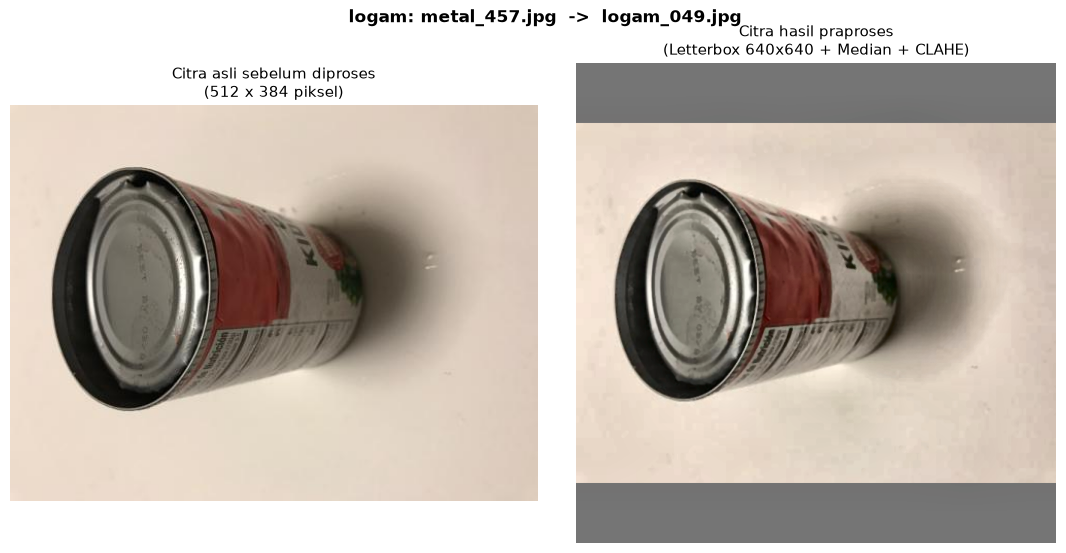

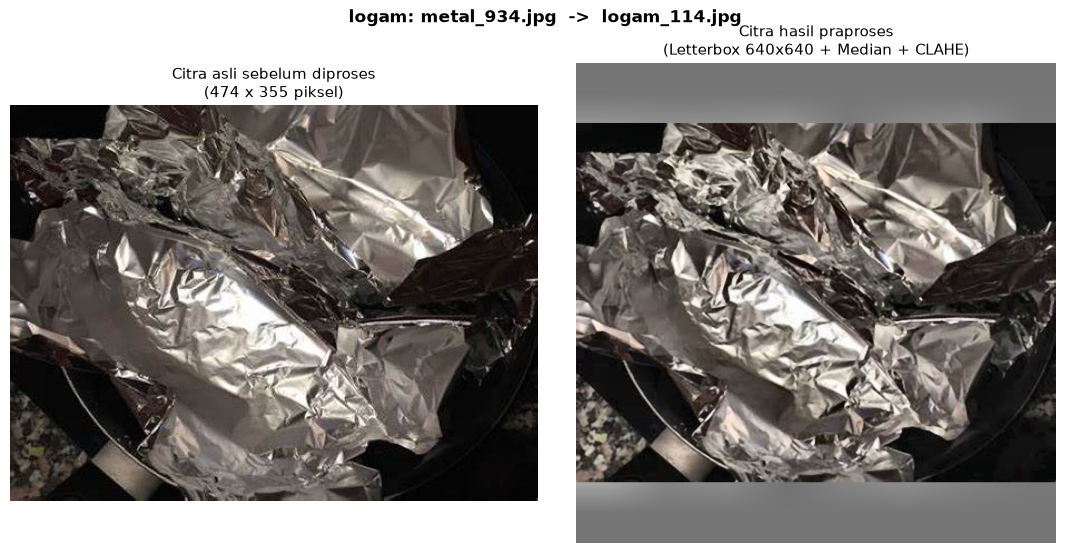

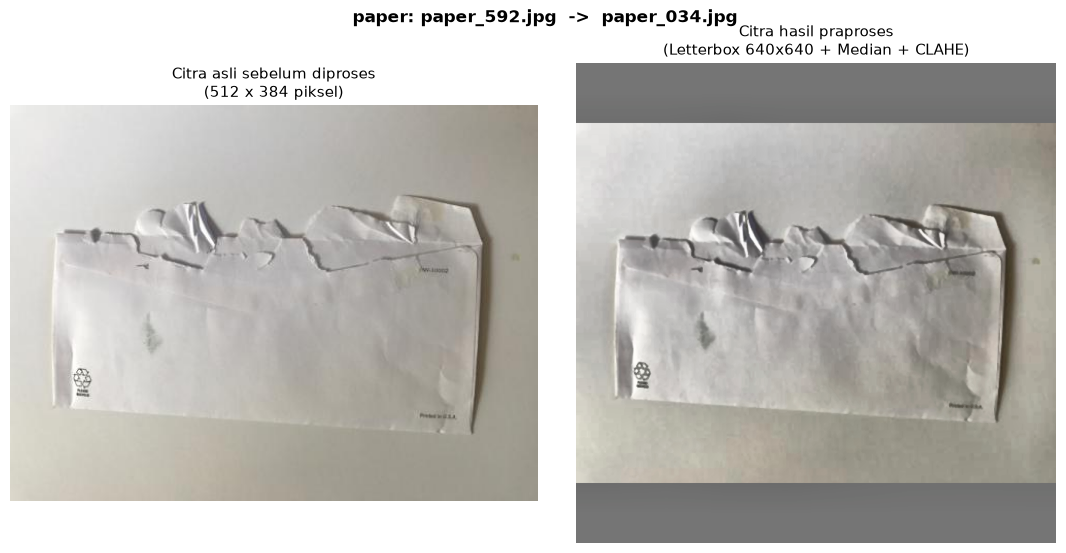

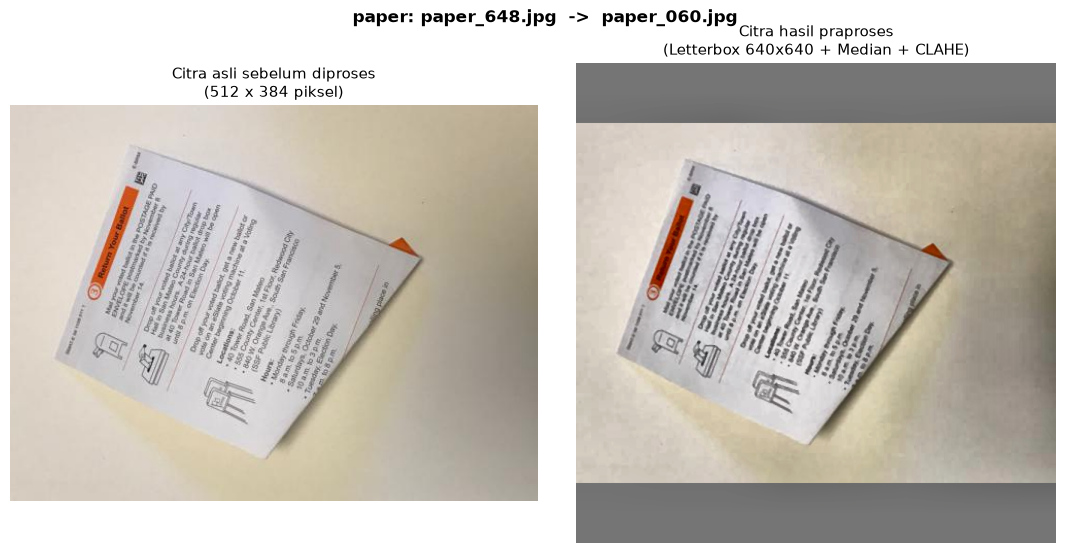

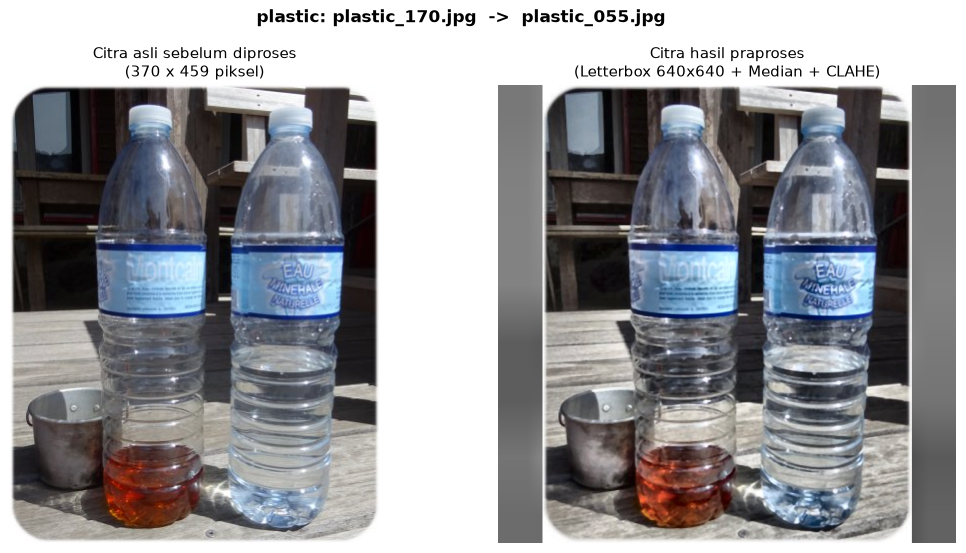

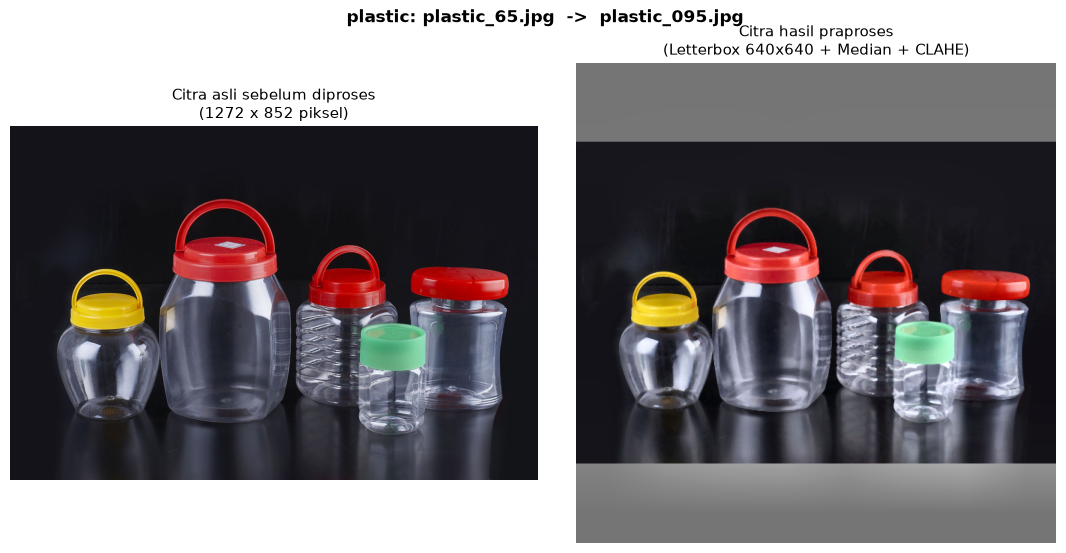

In [4]:
def gambar_banding(r, asli, hasil):
    fig, ax = plt.subplots(1, 2, figsize=(11, 5.6))
    ax[0].imshow(cv2.cvtColor(asli, cv2.COLOR_BGR2RGB))
    ax[0].set_title(f"Citra asli sebelum diproses\n({asli.shape[1]} x {asli.shape[0]} piksel)", fontsize=11)
    ax[1].imshow(cv2.cvtColor(hasil, cv2.COLOR_BGR2RGB))
    ax[1].set_title("Citra hasil praproses\n(Letterbox 640x640 + Median + CLAHE)", fontsize=11)
    for a in ax:
        a.axis("off")
    fig.suptitle(f"{r.kelas}: {r.nama_asli}  ->  {r.nama_baru}", fontsize=12, fontweight="bold")
    fig.tight_layout()
    return fig


contoh = set(pd.concat([g.sample(min(JUMLAH_CONTOH, len(g)), random_state=1)
                        for _, g in tabel.groupby("kelas")])["nama_baru"])
statistik = []

for r in tabel.itertuples():
    if r.nama_baru not in contoh and not SIMPAN_SEMUA:
        continue
    asli = baca(DATASET_RAW / r.kelas / r.nama_asli)
    hasil, kotak, lb = praproses(asli)
    fig = gambar_banding(r, asli, hasil)
    if SIMPAN_SEMUA:
        (HASIL / "perbandingan").mkdir(parents=True, exist_ok=True)
        fig.savefig(HASIL / "perbandingan" / (r.nama_baru.replace(".jpg", ".png")), dpi=90)
    if r.nama_baru in contoh:
        plt.show()
        x1, y1, x2, y2 = kotak
        l_sebelum = cv2.cvtColor(lb, cv2.COLOR_BGR2LAB)[y1:y2, x1:x2, 0]
        l_sesudah = cv2.cvtColor(hasil, cv2.COLOR_BGR2LAB)[y1:y2, x1:x2, 0]
        statistik.append(dict(file=r.nama_baru, L_rata_sebelum=l_sebelum.mean(), L_rata_sesudah=l_sesudah.mean(),
                              L_std_sebelum=l_sebelum.std(), L_std_sesudah=l_sesudah.std()))
    plt.close(fig)

## 5. Perubahan kecerahan dan kontras pada contoh di atas


In [5]:
display(pd.DataFrame(statistik).round(2))

,file,L_rata_sebelum,L_rata_sesudah,L_std_sebelum,L_std_sesudah
0,logam_049.jpg,177.34,180.42,62.87,60.70
1,logam_114.jpg,82.50,95.41,63.68,68.23
2,paper_034.jpg,189.19,178.98,26.05,27.30
3,paper_060.jpg,195.49,188.64,24.78,32.03
4,plastic_055.jpg,113.60,118.66,69.62,69.91
5,plastic_095.jpg,51.94,63.03,51.03,61.83
